<p>code adapted from https://www.freecodecamp.org/news/how-to-preprocess-medical-images-for-machine-learning/</p>

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
import pandas as pd
import shutil

In [2]:
# set up file paths
BASE_DIR = "/home/darren/Desktop/final_project/data"

# load CSV
df = pd.read_csv(os.path.join(BASE_DIR, "mass_case(with_jpg_img).csv"))

# get first image path and fix it
sample_path = os.path.join(BASE_DIR, df['jpg_fullMammo_img_path'].iloc[0])

sample_image = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)

print(f"Image shape: {sample_image.shape}")
print(f"Pixel range: {sample_image.min()} to {sample_image.max()}")
print(f"Data type: {sample_image.dtype}")

Image shape: (4808, 3024)
Pixel range: 0 to 255
Data type: uint8


In [3]:
# validate dataset in batches to prevent freeezing
def validate_dataset_batched(image_paths, batch_size=100):
    """Validate images in batches to avoid freezing."""
    corrupted = []
    too_small = []
    nearly_black = []
    total = len(image_paths)
    
    for i in range(0, total, batch_size):
        batch = image_paths[i:i+batch_size]
        print(f"Processing batch {i//batch_size + 1}/{(total + batch_size - 1)//batch_size}...")
        
        for fpath in batch:
            try:
                img = cv2.imread(fpath, cv2.IMREAD_GRAYSCALE)
                if img is None:
                    corrupted.append(fpath)
                    continue
                if img.shape[0] < 100 or img.shape[1] < 100:
                    too_small.append(fpath)
                if img.mean() < 5:
                    nearly_black.append(fpath)
            except Exception:
                corrupted.append(fpath)
    
    print(f"\nTotal files scanned: {total}")
    print(f"Corrupted: {len(corrupted)}")
    print(f"Too small: {len(too_small)}")
    print(f"Nearly black: {len(nearly_black)}")
    return corrupted, too_small, nearly_black

# Run validation in batches
image_paths = [os.path.join(BASE_DIR, path) for path in df['jpg_fullMammo_img_path']]
corrupted, too_small, nearly_black = validate_dataset_batched(image_paths)

Processing batch 1/17...
Processing batch 2/17...
Processing batch 3/17...
Processing batch 4/17...
Processing batch 5/17...
Processing batch 6/17...
Processing batch 7/17...
Processing batch 8/17...
Processing batch 9/17...
Processing batch 10/17...
Processing batch 11/17...
Processing batch 12/17...
Processing batch 13/17...
Processing batch 14/17...
Processing batch 15/17...
Processing batch 16/17...
Processing batch 17/17...

Total files scanned: 1696
Corrupted: 0
Too small: 0
Nearly black: 0


In [4]:
# scale images
sample_path = os.path.join(BASE_DIR, df['jpg_fullMammo_img_path'].iloc[0])
image = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)

# Scale to [0, 1]
image_scaled = image.astype(np.float32) / 255.0

print(f"Before scaling: {image.min()} to {image.max()}")
print(f"After scaling:  {image_scaled.min():.3f} to {image_scaled.max():.3f}")

Before scaling: 0 to 255
After scaling:  0.000 to 1.000


In [5]:
def compute_train_stats(image_paths, sample_limit=30):
    """Compute pixel mean and std from resized images to save memory."""
    pixel_values = []
    count = 0
    
    print(f"Computing stats from {sample_limit} images (resized to 224x224)...")
    
    for path in image_paths:
        if count >= sample_limit:
            break
        
        try:
            # Read image
            img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
            
            # Resize to small size before flattening 
            img_resized = cv2.resize(img, (224, 224))
            
            # Scale to [0, 1] and flatten
            img_flat = img_resized.astype(np.float32).flatten() / 255.0
            pixel_values.extend(img_flat)
            count += 1
            
            print(f"  Processed {count} images...")
                
        except Exception as e:
            print(f"  Error with {path}: {e}")
            continue
    
    # Convert to numpy array
    pixels = np.array(pixel_values, dtype=np.float32)
    mean, std = pixels.mean(), pixels.std()
    
    print(f"Done! Mean: {mean:.4f}, Std: {std:.4f}")
    return mean, std

# Use only 30 images, resized to 224x224
train_paths = [os.path.join(BASE_DIR, path) for path in df['jpg_fullMammo_img_path']]
train_mean, train_std = compute_train_stats(train_paths, sample_limit=30)

# normalize and resize sample image 
sample_path = os.path.join(BASE_DIR, df['jpg_fullMammo_img_path'].iloc[0])
image = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)
image_resized = cv2.resize(image, (224, 224))
image_scaled = image_resized.astype(np.float32) / 255.0
image_normalized = (image_scaled - train_mean) / train_std

print(f"Normalized pixel range: {image_normalized.min():.3f} to {image_normalized.max():.3f}")

Computing stats from 30 images (resized to 224x224)...
  Processed 1 images...
  Processed 2 images...
  Processed 3 images...
  Processed 4 images...
  Processed 5 images...
  Processed 6 images...
  Processed 7 images...
  Processed 8 images...
  Processed 9 images...
  Processed 10 images...
  Processed 11 images...
  Processed 12 images...
  Processed 13 images...
  Processed 14 images...
  Processed 15 images...
  Processed 16 images...
  Processed 17 images...
  Processed 18 images...
  Processed 19 images...
  Processed 20 images...
  Processed 21 images...
  Processed 22 images...
  Processed 23 images...
  Processed 24 images...
  Processed 25 images...
  Processed 26 images...
  Processed 27 images...
  Processed 28 images...
  Processed 29 images...
  Processed 30 images...
Done! Mean: 0.2173, Std: 0.2626
Normalized pixel range: -0.828 to 2.980


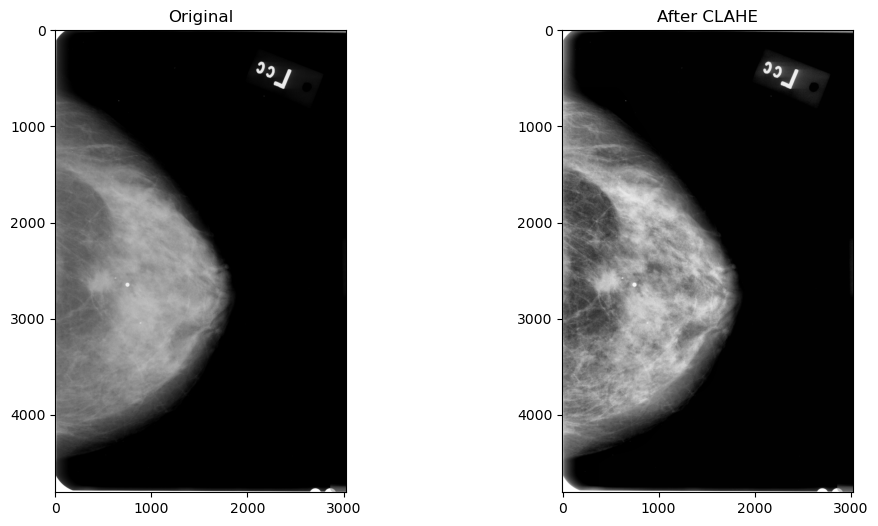

In [6]:
# CLAHE local contrast enhancement
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
image_enhanced = clahe.apply(image)

# Visualize difference
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(image, cmap='gray')
axes[0].set_title('Original')
axes[1].imshow(image_enhanced, cmap='gray')
axes[1].set_title('After CLAHE')
plt.show()

In [7]:
def is_valid_image(path):
    """Check if an image is valid (not corrupted, too small, or nearly black)."""
    try:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            return False
        if img.mean() < 5:           # nearly black
            return False
        if img.shape[0] < 50 or img.shape[1] < 50:  # too small
            return False
        return True
    except Exception:
        return False

# Test on sample image
sample_path = os.path.join(BASE_DIR, df['jpg_fullMammo_img_path'].iloc[0])
print(f"Sample image valid: {is_valid_image(sample_path)}")

Sample image valid: True


In [8]:
TARGET_SIZE = (224, 224)

def resize_with_padding(image, target_size):
    """Resize image while preserving aspect ratio by adding black padding."""
    h, w = image.shape[:2]
    target_h, target_w = target_size
    scale = min(target_h / h, target_w / w)
    new_h, new_w = int(h * scale), int(w * scale)
    resized = cv2.resize(image, (new_w, new_h))
    
    pad_h = target_h - new_h
    pad_w = target_w - new_w
    top, bottom = pad_h // 2, pad_h - pad_h // 2
    left, right = pad_w // 2, pad_w - pad_w // 2
    padded = cv2.copyMakeBorder(resized, top, bottom, left, right,
                                 cv2.BORDER_CONSTANT, value=0)
    return padded

# Apply to sample image
image_resized = resize_with_padding(image, TARGET_SIZE)
print(f"Resized shape: {image_resized.shape}")

Resized shape: (224, 224)


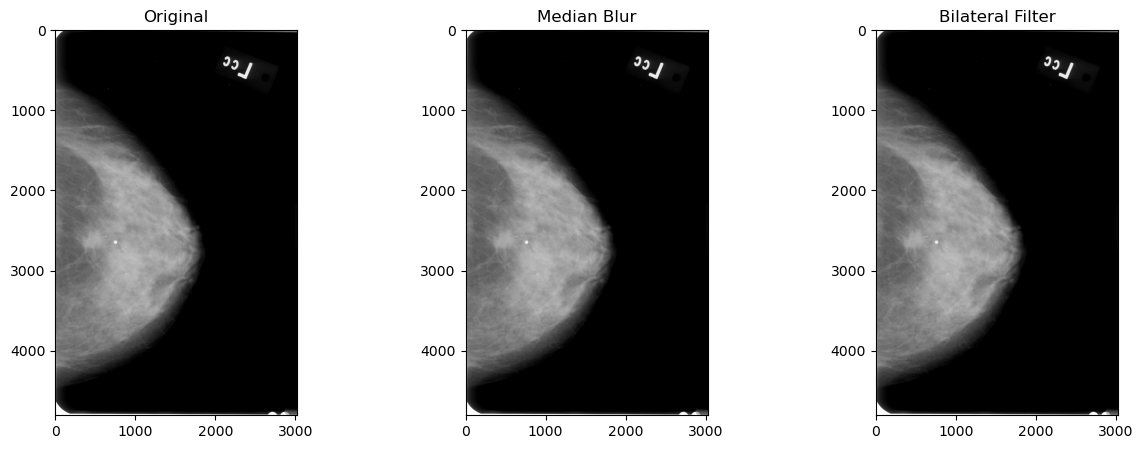

In [9]:
# Gentle denoising 
image_denoised = cv2.medianBlur(image, ksize=3)

# Bilateral filter (preserve edges better)
image_bilateral = cv2.bilateralFilter(image, d=5, sigmaColor=50, sigmaSpace=50)

# Visualize difference
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image, cmap='gray')
axes[0].set_title('Original')
axes[1].imshow(image_denoised, cmap='gray')
axes[1].set_title('Median Blur')
axes[2].imshow(image_bilateral, cmap='gray')
axes[2].set_title('Bilateral Filter')
plt.show()

In [10]:
def preprocess_mammogram(image_path, target_size=(224, 224),
                         train_mean=0.482, train_std=0.236):
    """
    Full preprocessing pipeline for CBIS-DDSM mammograms.
    Applies all six pillars in order.
    """
    # Validate first — skip corrupted files
    if not is_valid_image(image_path):
        return None
    
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    
    # resize with aspect ratio preserved
    image = resize_with_padding(image, target_size)
    
    # Gentle denoising
    image = cv2.medianBlur(image, 3)
    
    # Enhance contrast with CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    image = clahe.apply(image)
    
    # Scale to [0, 1]
    image = image.astype(np.float32) / 255.0
    
    # Normalize using training set statistics
    image = (image - train_mean) / train_std
    
    return image

# Test on sample image
sample_path = os.path.join(BASE_DIR, df['jpg_fullMammo_img_path'].iloc[0])
processed = preprocess_mammogram(sample_path, train_mean=train_mean, train_std=train_std)

if processed is not None:
    print(f"Processed image shape: {processed.shape}")
    print(f"Pixel range: {processed.min():.3f} to {processed.max():.3f}")
else:
    print("Image failed validation")

Processed image shape: (224, 224)
Pixel range: -0.798 to 2.980


In [14]:
# Create labels from dataframe
y = df['pathology'].apply(lambda x: 1 if 'MALIGNANT' in str(x).upper() else 0).values

# Process dataset
image_paths = [os.path.join(BASE_DIR, path) for path in df['jpg_fullMammo_img_path']]
X_processed, valid_paths = process_all_images(image_paths, train_mean=train_mean, train_std=train_std)

print(f"\nFinal dataset shape: {X_processed.shape}")

# Create folders
SAVE_DIR = "/home/darren/Desktop/final_project/processed_data"
os.makedirs(SAVE_DIR, exist_ok=True)

# Split into train/val/test (60/20/20)
X_temp, X_test, y_temp, y_test = train_test_split(
    X_processed, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

# Save numpy arrays
np.save(os.path.join(SAVE_DIR, 'X_train.npy'), X_train)
np.save(os.path.join(SAVE_DIR, 'y_train.npy'), y_train)
np.save(os.path.join(SAVE_DIR, 'X_val.npy'), X_val)
np.save(os.path.join(SAVE_DIR, 'y_val.npy'), y_val)
np.save(os.path.join(SAVE_DIR, 'X_test.npy'), X_test)
np.save(os.path.join(SAVE_DIR, 'y_test.npy'), y_test)

print(f"Saved to: {SAVE_DIR}")
print(f"Train: {X_train.shape[0]}, Val: {X_val.shape[0]}, Test: {X_test.shape[0]}")

Processing 1696 images...
  Progress: 0/1696
  Progress: 100/1696
  Progress: 200/1696
  Progress: 300/1696
  Progress: 400/1696
  Progress: 500/1696
  Progress: 600/1696
  Progress: 700/1696
  Progress: 800/1696
  Progress: 900/1696
  Progress: 1000/1696
  Progress: 1100/1696
  Progress: 1200/1696
  Progress: 1300/1696
  Progress: 1400/1696
  Progress: 1500/1696
  Progress: 1600/1696
Done! Successfully processed 1696/1696 images

Final dataset shape: (1696, 224, 224)
Saved to: /home/darren/Desktop/final_project/processed_data
Train: 1017, Val: 339, Test: 340
